In [3]:
import pandas as pd

# 1. 파일 읽기 및 df에 할당
df = pd.read_csv('../meft_2014-2025.csv')
df.약효분류코드  =df.약효분류코드.astype(int).astype(str)
df.head()

,약효분류코드,약효분류명,진료년월,연도,월,수량_천개,사용금액_백만원
0,111,전신마취제,2014-01,2014,1,6176.0,2754.0
1,111,전신마취제,2014-02,2014,2,5747.0,2567.0
2,111,전신마취제,2014-03,2014,3,5813.0,2579.0
3,111,전신마취제,2014-04,2014,4,5587.0,2466.0
4,111,전신마취제,2014-05,2014,5,5370.0,2377.0


In [5]:
assert not df.duplicated(['약효분류코드', '진료년월']).any(), "분류코드별 월 중복 존재"

df.duplicated(['약효분류코드', '진료년월']).sum()

np.int64(0)

## 중복 하나도 없음

In [6]:
# 2025.12 기준 최근 36개월 목록 생성 (2023년 1월 ~ 2025년 12월)
months_36 = [f'{y}-{m:02d}' for y in range(2023, 2026) for m in range(1, 13)]
df_36 = df[df['진료년월'].isin(months_36)]

# 약효분류코드별, 진료년월별 피벗 테이블 생성
piv_amt = df_36.pivot(
    index='약효분류코드', columns='진료년월', values='사용금액_백만원'
)
piv_qty = df_36.pivot(
    index='약효분류코드', columns='진료년월', values='수량_천개'
)

all_codes = df['약효분류코드'].unique()
piv_amt = piv_amt.reindex(index=all_codes, columns=months_36)
piv_qty = piv_qty.reindex(index=all_codes, columns=months_36)

# 사용금액 또는 수량이 결측치(Null)인 경우를 True로 하는 마스크 생성
null_mask = piv_amt.isna() | piv_qty.isna()

# 약효분류코드와 약효분류명 매핑 딕셔너리
code_name_map = df.drop_duplicates('약효분류코드').set_index('약효분류코드')[
    '약효분류명'
]

# 1. 최근 36개월 동안 사용금액, 사용량 값이 null이 없는 분류코드
no_null_36 = null_mask.sum(axis=1) == 0
codes_no_null = piv_amt.index[no_null_36].tolist()

print(f"36개월 동안 Not Null인 분류코드 개수: {len(codes_no_null)}")
# display(codes_no_null[:10])
# display(piv_amt.loc[codes_no_null].head())
# display(piv_qty.loc[codes_no_null].head())


# 2. 최근 36개월 동안 null이 있는 분류코드
has_null_36 = null_mask.sum(axis=1) > 0
codes_has_null = piv_amt.index[has_null_36].tolist()
print(f"36개월 동안 Null가진 분류코드 개수: {len(codes_has_null)}")

# 3. 최근 36개월 동안 null이 있는 분류코드 중 2025.12의 값이 null인 분류코드
dec_null = null_mask['2025-12']
codes_has_null_and_dec_null = piv_amt.index[has_null_36 & dec_null].tolist()
print(f"36개월 동안 Null가진 분류코드 중 2025.12 Null인 개수: {len(codes_has_null_and_dec_null)}")

# 4. 최근 36개월 동안 null이 있는 분류코드지만 2025.12에 not null인 분류코드 중 최근 36개월 내 값이 not null에서 null로 전환된 횟수
subset_codes = piv_amt.index[has_null_36 & ~dec_null]
transitions_results = []
for code in subset_codes:
  row = null_mask.loc[code].astype(bool)
  prev = row.shift(1).fillna(False)
  trans_count = int((~prev & row).sum())
  transitions_results.append(
      {
          '약효분류코드': code,
          '약효분류명': code_name_map.get(code, ''),
          '전환횟수': trans_count,
      }
  )

print(f"36개월 동안 Null가진 분류코드 중 2025.12 Not Null인 개수: {len(codes_has_null)-len(codes_has_null_and_dec_null)}")
df_trans = pd.DataFrame(transitions_results)
df_trans.sort_values(by='전환횟수', ascending=False)

36개월 동안 Not Null인 분류코드 개수: 117
36개월 동안 Null가진 분류코드 개수: 16
36개월 동안 Null가진 분류코드 중 2025.12 Null인 개수: 9
36개월 동안 Null가진 분류코드 중 2025.12 Not Null인 개수: 7


,약효분류코드,약효분류명,전환횟수
2,712,연고기제,8
0,262,창상보호제,6
6,310,비타민제,4
1,633,항독소 및 렙토스피라혈청류,1
3,140,알레르기용약,1
4,230,소화기관용약,1
5,250,비뇨생식기관 및 항문용약,1


In [7]:
# 3번 그룹: 36개월 내 Null이 있고 2025.12 값이 Null인 분류코드
codes_group3 = piv_amt.index[has_null_36 & dec_null].tolist()

# --- [위 3번 분류코드 분석] ---
res_group3 = []
for code in codes_group3:
  row = null_mask.loc[code]
  not_null_months = [m for m in months_36 if not row[m]]
  last_observed = not_null_months[-1] if not_null_months else None

  if last_observed:
    p_last = pd.to_datetime(last_observed + '-01')
    p_target = pd.to_datetime('2025-12-01')
    diff_months = (p_target.year - p_last.year) * 12 + (
        p_target.month - p_last.month
    )
  else:
    diff_months = None

  # 연속 결측 구간 길이 계산
  null_series = row.astype(int)
  groups = (null_series != null_series.shift()).cumsum()
  consecutive_null_lengths = [
      int(g_df.sum()) for g_id, g_df in null_series.groupby(groups) if g_df.iloc[0] == 1
  ]

  res_group3.append(
      {
          '약효분류코드': code,
          '약효분류명': code_name_map.get(code, ''),
          '최종관측날짜': last_observed,
          '2025.12까지의기간(개월)': diff_months,
          '연속결측구간_길이목록': consecutive_null_lengths,
      }
  )

df_res3 = pd.DataFrame(res_group3).sort_values(by='연속결측구간_길이목록', ascending=False)
display(df_res3)


,약효분류코드,약효분류명,최종관측날짜,2025.12까지의기간(개월),연속결측구간_길이목록
0,210,순환계용약,NaN,NaN,[36]
5,719,기타의 조제용약,NaN,NaN,[36]
6,732,방역용 살균소독제,NaN,NaN,[36]
7,739,기타의 공중위생용약,NaN,NaN,[36]
8,393,습관성중독용제,NaN,NaN,[36]
3,326,장기제제,2023-01,35.0,[35]
4,398,종합대사성제제,2023-09,27.0,"[8, 27]"
2,267,"모발용제(발모,탈모,염모,양모제)",2023-11,25.0,"[6, 1, 25]"
1,246,남성호르몬제,2025-07,5.0,"[1, 1, 1, 1, 3, 1, 3, 4, 2, 5]"


In [8]:
# 4번 그룹: 36개월 내 Null이 있고 2025.12 값이 Not Null인 분류코드
codes_group4 = piv_amt.index[has_null_36 & ~dec_null].tolist()

# --- [위 4번 분류코드 분석] ---
res_group4 = []
for code in codes_group4:
  row = null_mask.loc[code]
  null_months = [m for m in months_36 if row[m]]

  if null_months:
    last_null_month = null_months[-1]
    sub_months = [m for m in months_36 if m > last_null_month and not row[m]]
    first_obs_after_last_null = sub_months[0] if sub_months else '2025-12'

    p_null = pd.to_datetime(last_null_month + '-01')
    p_obs = pd.to_datetime(first_obs_after_last_null + '-01')
    diff_months = (p_obs.year - p_null.year) * 12 + (p_obs.month - p_null.month)
  else:
    last_null_month = None
    diff_months = None

  null_series = row.astype(int)
  groups = (null_series != null_series.shift()).cumsum()
  consecutive_null_lengths = [
      int(g_df.sum()) for g_id, g_df in null_series.groupby(groups) if g_df.iloc[0] == 1
  ]

  res_group4.append(
      {
          '약효분류코드': code,
          '약효분류명': code_name_map.get(code, ''),
          '최종결측날짜': last_null_month,
          '결측후관측재개까지의기간(개월)': diff_months,
          '연속결측구간_길이목록': consecutive_null_lengths,
      }
  )

df_res4 = pd.DataFrame(res_group4).sort_values(by='연속결측구간_길이목록', ascending=False)
display(df_res4)    

,약효분류코드,약효분류명,최종결측날짜,결측후관측재개까지의기간(개월),연속결측구간_길이목록
4,230,소화기관용약,2025-05,1,[29]
3,140,알레르기용약,2024-08,1,[20]
6,310,비타민제,2025-11,1,"[7, 7, 2, 16]"
5,250,비뇨생식기관 및 항문용약,2023-06,1,[6]
0,262,창상보호제,2025-04,1,"[2, 1, 1, 1, 1, 1]"
2,712,연고기제,2025-11,1,"[1, 1, 5, 2, 4, 1, 2, 2]"
1,633,항독소 및 렙토스피라혈청류,2025-02,1,[1]


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- [중요] 폰트 설정 (한글/CJK 깨짐 방지) ---
plt.rcParams['font.family'] = (
    'Noto Sans CJK JP'  # 리눅스 환경에 설치된 CJK 지원 폰트 지정
)
# 마이너스 기호 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False  # bool 값만 허용; 문자열 'Minus sign'은 에러

# 1. 데이터 필터링 및 극단적 코드(36개월 전결측 5개 + 35개월 결측 1개) 제외
exclude_codes = [210.0, 719.0, 732.0, 739.0, 393.0, 326.0]
valid_target_codes = [c for c in codes_has_null if c not in exclude_codes]

metrics_data = []
for code in valid_target_codes:
  row = null_mask.loc[code]
  null_count = int(row.sum())

  # 연속 결측 구간(스펠) 분석
  null_series = row.astype(int)
  groups = (null_series != null_series.shift()).cumsum()
  null_intervals = [
      int(g_df.sum()) for g_id, g_df in null_series.groupby(groups) if g_df.iloc[0] == 1
  ]

  num_spells = len(null_intervals)
  avg_duration = null_count / num_spells if num_spells > 0 else 0
  null_ratio = (null_count / 36) * 100

  metrics_data.append(
      {
          '약효분류코드': code,
          '약효분류명': code_name_map.get(code, ''),
          '결측반복횟수': num_spells,
          '평균결측지속기간': round(avg_duration, 2),
          '총결측월수': null_count,
          '결측비율(%)': round(null_ratio, 1),
      }
  )

df_metrics = pd.DataFrame(metrics_data)
df_metrics = df_metrics[df_metrics['총결측월수'] < 36]  # 결측 월수가 36개월 미만인 경우만 포함
df_metrics.sort_values( by=['결측비율(%)', '평균결측지속기간'],ascending=[False, False], inplace=True)
print('--- 10개 대상 코드 결측 지표 요약 ---')
display(df_metrics.reset_index(drop=True))


--- 10개 대상 코드 결측 지표 요약 ---


,약효분류코드,약효분류명,결측반복횟수,평균결측지속기간,총결측월수,결측비율(%)
0,326,장기제제,1,35.00,35,97.2
1,398,종합대사성제제,2,17.50,35,97.2
2,267,"모발용제(발모,탈모,염모,양모제)",3,10.67,32,88.9
3,310,비타민제,4,8.00,32,88.9
4,230,소화기관용약,1,29.00,29,80.6
5,246,남성호르몬제,10,2.20,22,61.1
6,140,알레르기용약,1,20.00,20,55.6
7,712,연고기제,8,2.25,18,50.0
8,262,창상보호제,6,1.17,7,19.4
9,250,비뇨생식기관 및 항문용약,1,6.00,6,16.7


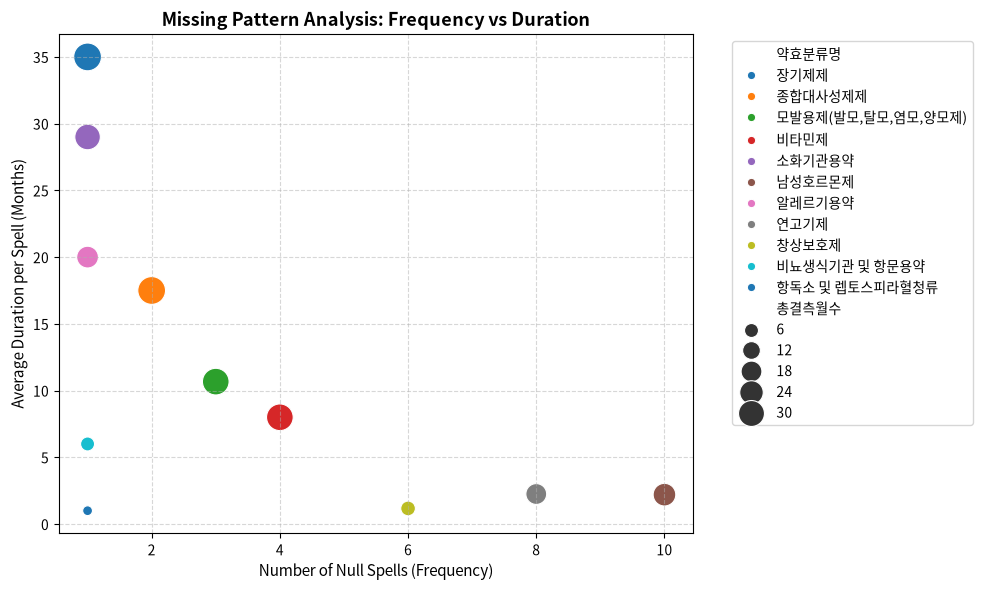

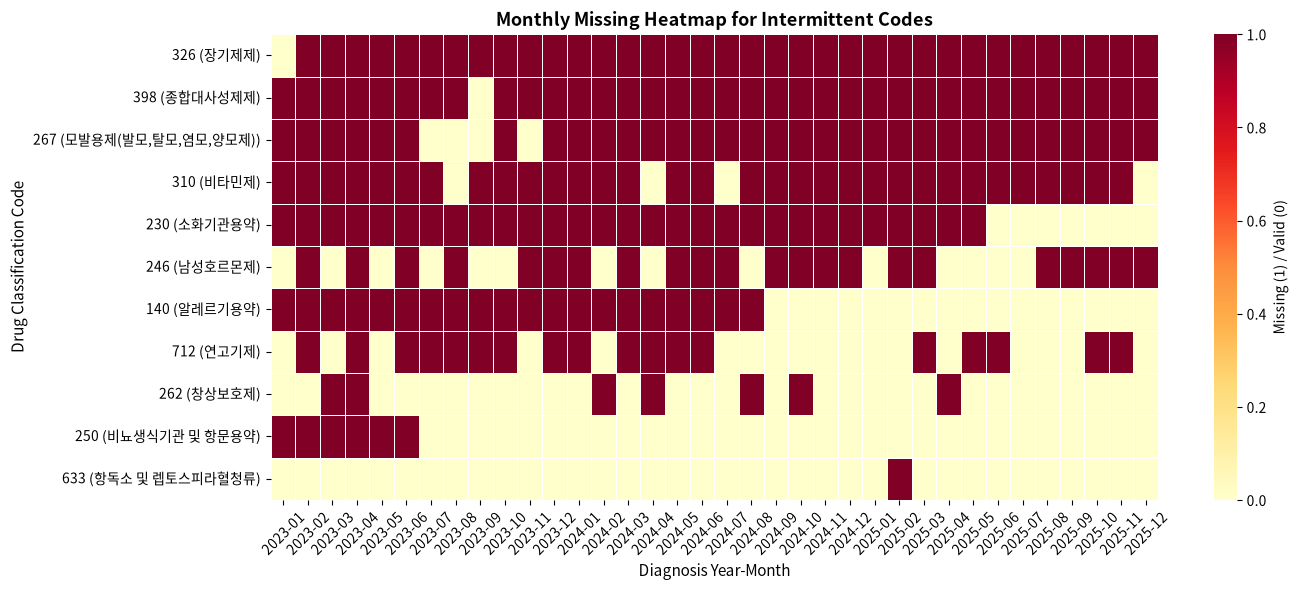

In [10]:

# 2. 시각화 1: 산점도 (반복 횟수 vs 평균 지속 기간)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_metrics,
    x='결측반복횟수',
    y='평균결측지속기간',
    size='총결측월수',
    hue='약효분류명',
    sizes=(50, 400),
    palette='tab10',
)
plt.title(
    'Missing Pattern Analysis: Frequency vs Duration',
    fontsize=13,
    weight='bold',
)
plt.xlabel('Number of Null Spells (Frequency)', fontsize=11)
plt.ylabel('Average Duration per Spell (Months)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('missing_pattern_scatter.png')
plt.show()

# 3. 시각화 2: 히트맵 (10개 코드의 월별 결측 분포)
plt.figure(figsize=(14, 6))
heatmap_data = null_mask.loc[df_metrics['약효분류코드']].astype(int)
heatmap_data.index = [
    f'{c} ({code_name_map.get(c, "")})' for c in df_metrics['약효분류코드']
]

sns.heatmap(
    heatmap_data,
    cmap='YlOrRd',
    cbar_kws={'label': 'Missing (1) / Valid (0)'},
    linewidths=0.5,
)
plt.title(
    'Monthly Missing Heatmap for Intermittent Codes',
    fontsize=13,
    weight='bold',
)
plt.xlabel('Diagnosis Year-Month', fontsize=11)
plt.ylabel('Drug Classification Code', fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('missing_pattern_heatmap.png')
plt.show()

<Figure size 3000x500 with 0 Axes>

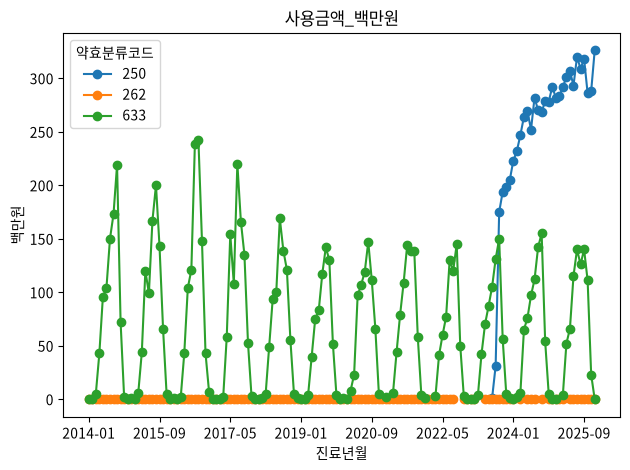

<Figure size 1000x500 with 0 Axes>

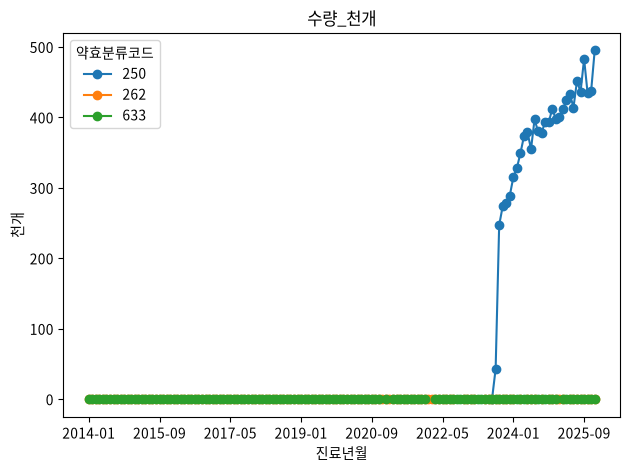

In [22]:
# 1. 사용할 데이터 추출 및 피벗
df_target = df[df['약효분류코드'].isin(['250', '633','262'])]

piv_amt = df_target.pivot(
    index='진료년월', columns='약효분류코드', values='사용금액_백만원'
)
piv_qty = df_target.pivot(
    index='진료년월', columns='약효분류코드', values='수량_천개'
)

# 2. 사용금액 그래프
plt.figure(figsize=(30, 5))
piv_amt.plot(marker='o')
plt.title('사용금액_백만원')
plt.ylabel('백만원')
plt.tight_layout()
plt.show()

# 3. 수량 그래프
plt.figure(figsize=(10, 5))
piv_qty.plot(marker='o')
plt.title('수량_천개')
plt.ylabel('천개')
plt.tight_layout()
plt.show()

<Axes: xlabel='약효분류코드', ylabel='진료년월'>

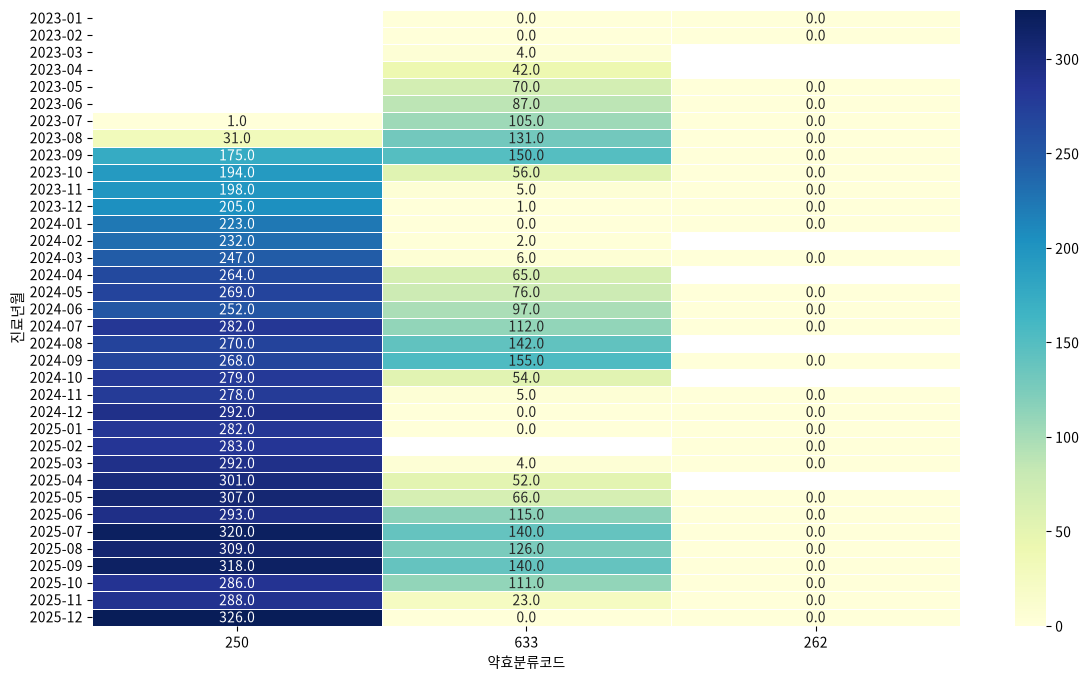

In [23]:
sub_piv = piv_amt.loc[months_36,('250','633','262')]

# 2. 한글 폰트 설정 (환경에 따라 필요시 주석 해제)
# import matplotlib
# matplotlib.rc('font', family='Malgun Gothic') # Windows
# matplotlib.rc('font', family='AppleGothic')    # Mac

plt.figure(figsize=(14, 8))

# 3. 히트맵 그리기
# annot=True: 셀 안에 실제 숫자를 표시함
# fmt='.1f': 소수점 첫 번째 자리까지 표시 (정수라면 '.0f' 또는 'd' 사용)
# cmap: 색상 팔레트 (YlGnBu, Blues 등)
# linewidths: 셀 사이의 간격 선
sns.heatmap(
    sub_piv, 
    annot=True, 
    fmt='.1f', 
    cmap='YlGnBu', 
    cbar=True, 
    linewidths=0.5,
    mask=sub_piv.isna() # NaN인 값은 기본적으로 빈 칸(색상 없음)으로 처리
)

## 26년 데이터 점검 결과
- 창상보호제(262)는 그 값이 극히 작고 0인 경우가 대부분이므로 제외확정!
- 항독소 약품(633)은 확실한 계절성 있으나 대부분 0으로 집계되는 기간이 많고 금액/수량의 규모가 매우 미미 하므로 결측치를 0으로 보정하거나 분석대상에서 제외 가능
- 생식기관 및 항문용약(250)은 수량이 500미만 수준으로 유지되고 있어 유의미한 수치이나 여전히 전체대비 규모가 작다. 

In [28]:
all_codes = df['약효분류코드'].unique()
piv_amt = piv_amt.reindex(index=all_codes, columns=months_36)
piv_qty = piv_qty.reindex(index=all_codes, columns=months_36)

# 36개월 모두 Not Null인 분류코드만 선택
valid_codes = null_mask.index[null_mask.sum(axis=1).eq(0)]

# 금액 또는 수량 중 하나라도 0이면 해당 월을 zero로 판정
zero_mask = piv_amt.loc[valid_codes].eq(0) | piv_qty.loc[valid_codes].eq(0)
display(zero_mask.sum(axis=1).sort_values(ascending=False).sum())


np.int64(0)

## 결측치가 없는 분류군은 zero도  없음 (최근 36개월 한정)